## TP2 Procesamiento del Habla: Procesamiento de archivos PDF

## Import de librerias

In [1]:
import pdfplumber
import pandas as pd
import requests
import os
import nltk
import re
import matplotlib.pyplot as plt

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

nltk.download('stopwords')

/home/dynazenon/Documents/TogeToge/ProcesamientoDelHabla/.venv/lib/python3.12/site-packages/nltk/downloader.py:1076: UserWarning: NLTK will not authorize the non-private download directory '/home/dynazenon/nltk_data': it (or an ancestor) is world- or group-writable, so another local user could plant files there. Choose a private location such as ~/nltk_data.
  for msg in self.incr_download(info_or_id, download_dir, force):
[nltk_data] Downloading package stopwords to
[nltk_data]     /home/dynazenon/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

# 1. Adquisición y metadatos

Informe realizado por INDEC: "Incidencia de la pobreza y la indigencia en 31 aglomerados urbanos"

In [2]:
URL_PDF = "https://www.indec.gob.ar/uploads/informesdeprensa/eph_pobreza_09_2670733F4C4D.pdf"
NOMBRE_ARCHIVO = "eph_pobreza.pdf"

respuesta = requests.get(URL_PDF)
print("Código de estado HTTP:", respuesta.status_code)

with open(NOMBRE_ARCHIVO, "wb") as f:
    f.write(respuesta.content)

tamano_kb = os.path.getsize(NOMBRE_ARCHIVO) / 1024
print(f"Archivo guardado como '{NOMBRE_ARCHIVO}' ({tamano_kb:.1f} KB)")

Código de estado HTTP: 200
Archivo guardado como 'eph_pobreza.pdf' (1896.7 KB)


In [3]:
pdf_plumber = pdfplumber.open(NOMBRE_ARCHIVO)

print("Tipo de objeto:", type(pdf_plumber))
print("Cantidad de páginas:", len(pdf_plumber.pages))

Tipo de objeto: <class 'pdfplumber.pdf.PDF'>
Cantidad de páginas: 20


In [4]:
metadata_plumber = pdf_plumber.metadata
metadata_plumber

{'Author': 'Instituto Nacional de Estadística y Censos (INDEC)',
 'CreationDate': "D:20260924150743-03'00'",
 'Creator': 'Adobe InDesign 21.6 (Windows)',
 'ModDate': "D:20260924151119-03'00'",
 'Producer': 'Adobe PDF Library 18.0',
 'Subject': 'Incidencia de la pobreza y la indigencia en 31 aglomerados urbanos. ',
 'Title': 'Incidencia de la pobreza y la indigencia en 31 aglomerados urbanos. Primer semestre de 2026',
 'Trapped': 'False'}

## 2. Análisis estructural del texto

Vemos la cantidad de caracteres y palabras dentro del documento y luego el contenido crudo de 5 paginas para ver como está armado el texto. La funcion "extract_text()" de pdfplunder nos facilita este trabajo.

In [5]:
texto_completo_plumber = ""

for pagina in pdf_plumber.pages:
    texto_pagina = pagina.extract_text()
    if texto_pagina:               # algunas páginas podrían no tener texto
        texto_completo_plumber += texto_pagina + "\n"

print("Cantidad de caracteres extraídos (pdfplumber):", len(texto_completo_plumber))
print("Cantidad de palabras aproximada:", len(texto_completo_plumber.split()))

Cantidad de caracteres extraídos (pdfplumber): 50430
Cantidad de palabras aproximada: 7992


In [6]:
numero_paginas = [1, 2, 4, 6, 8]
paginas = []

for numero in numero_paginas:
    pagina_plumber = pdf_plumber.pages[numero]
    paginas.append(pagina_plumber.extract_text())

In [7]:
for pagina in paginas:
    print(repr(pagina))

'Informes técnicos. Vol. 10, nº 238\nÍndice Pág.\nISSN 2545-6636\nResumen ejecutivo ...............................................................................................3\nCondiciones de vida. Vol. 10, nº 21\nIntroducción .........................................................................................................4\nISSN 2545-6660\nCuadros\nIncidencia de la pobreza y la\nCuadro 1. Pobreza e indigencia. Total 31 aglomerados urbanos ......................5\nindigencia en 31 aglomerados\nCuadro 2.1 Brecha de la indigencia. Total 31 aglomerados urbanos ..................7\nurbanos\nCuadro 2.2 Brecha de la pobreza. Total 31 aglomerados urbanos ......................7\nPrimer semestre de 2026 Cuadro 3.1 Población por condición de pobreza, según grupos de edad.\nPrimer semestre de 2026 ...............................................................8\nCuadro 3.2 Población por grupos de edad, según condición de pobreza.\nInstituto Nacional de Estadística y Censos\nPrimer s

- Las secciones se dividen mediante encabezados descriptivos, como "Resumen ejecutivo", "Pobreza" e "Indigencia".
- El principal separador es "\n", utilizado para representar los saltos de línea del texto.
- Los espacios simples " " separan palabras y valores.
- No hay "\t", "\r" ni "\n\n".
- Al final de cada pagina se ve el numero de la pagina "2/20", "4/20", etc.

## 3. Extracción de datos tabulares

Primero busco la pagina exacta donde está el grafico.

In [8]:
numero_pagina_tabla = 12

pagina_plumber_tabla = pdf_plumber.pages[numero_pagina_tabla]

In [9]:
pagina_plumber_tabla.extract_text()

'Anexo metodológico\nLa EPH es un programa nacional de producción sistemática y permanente de indicadores sociales que lleva a\ncabo el INDEC conjuntamente con las direcciones provinciales de estadística (DPE). Tiene por objeto relevar las\ncaracterísticas sociodemográficas y socioeconómicas de la población.\nCon relación a la medición de la pobreza, es necesario tener presente que la información que se difunde está producida\ncon la metodología de cálculo de la pobreza que se ha estado utilizando desde 1992, es decir, con una valorización\nde la canasta básica alimentaria (CBA) y de la canasta básica total (CBT) comparada con los ingresos de los hogares\nrelevados por la EPH. Desde 2016, la medición introdujo la actualización de la línea de indigencia y de pobreza con\nbase en la composición de la CBA resultante de la Encuesta Nacional de Gastos de los Hogares (ENGHo) 1996/97. Dicha\ncomposición fue validada, en términos de la estructura alimentaria, con el patrón de consumo que surge

Usar la funcion "extract_tables()" no funcionaba bien haciendoselo a la pagina normal. Por lo tanto uso la funcion "to_image()" para hacer la pagina una imagen y luego con  "debug_tablefinder()" puedo ir cambiando la configuracion y ver cual me da mejor resultado.

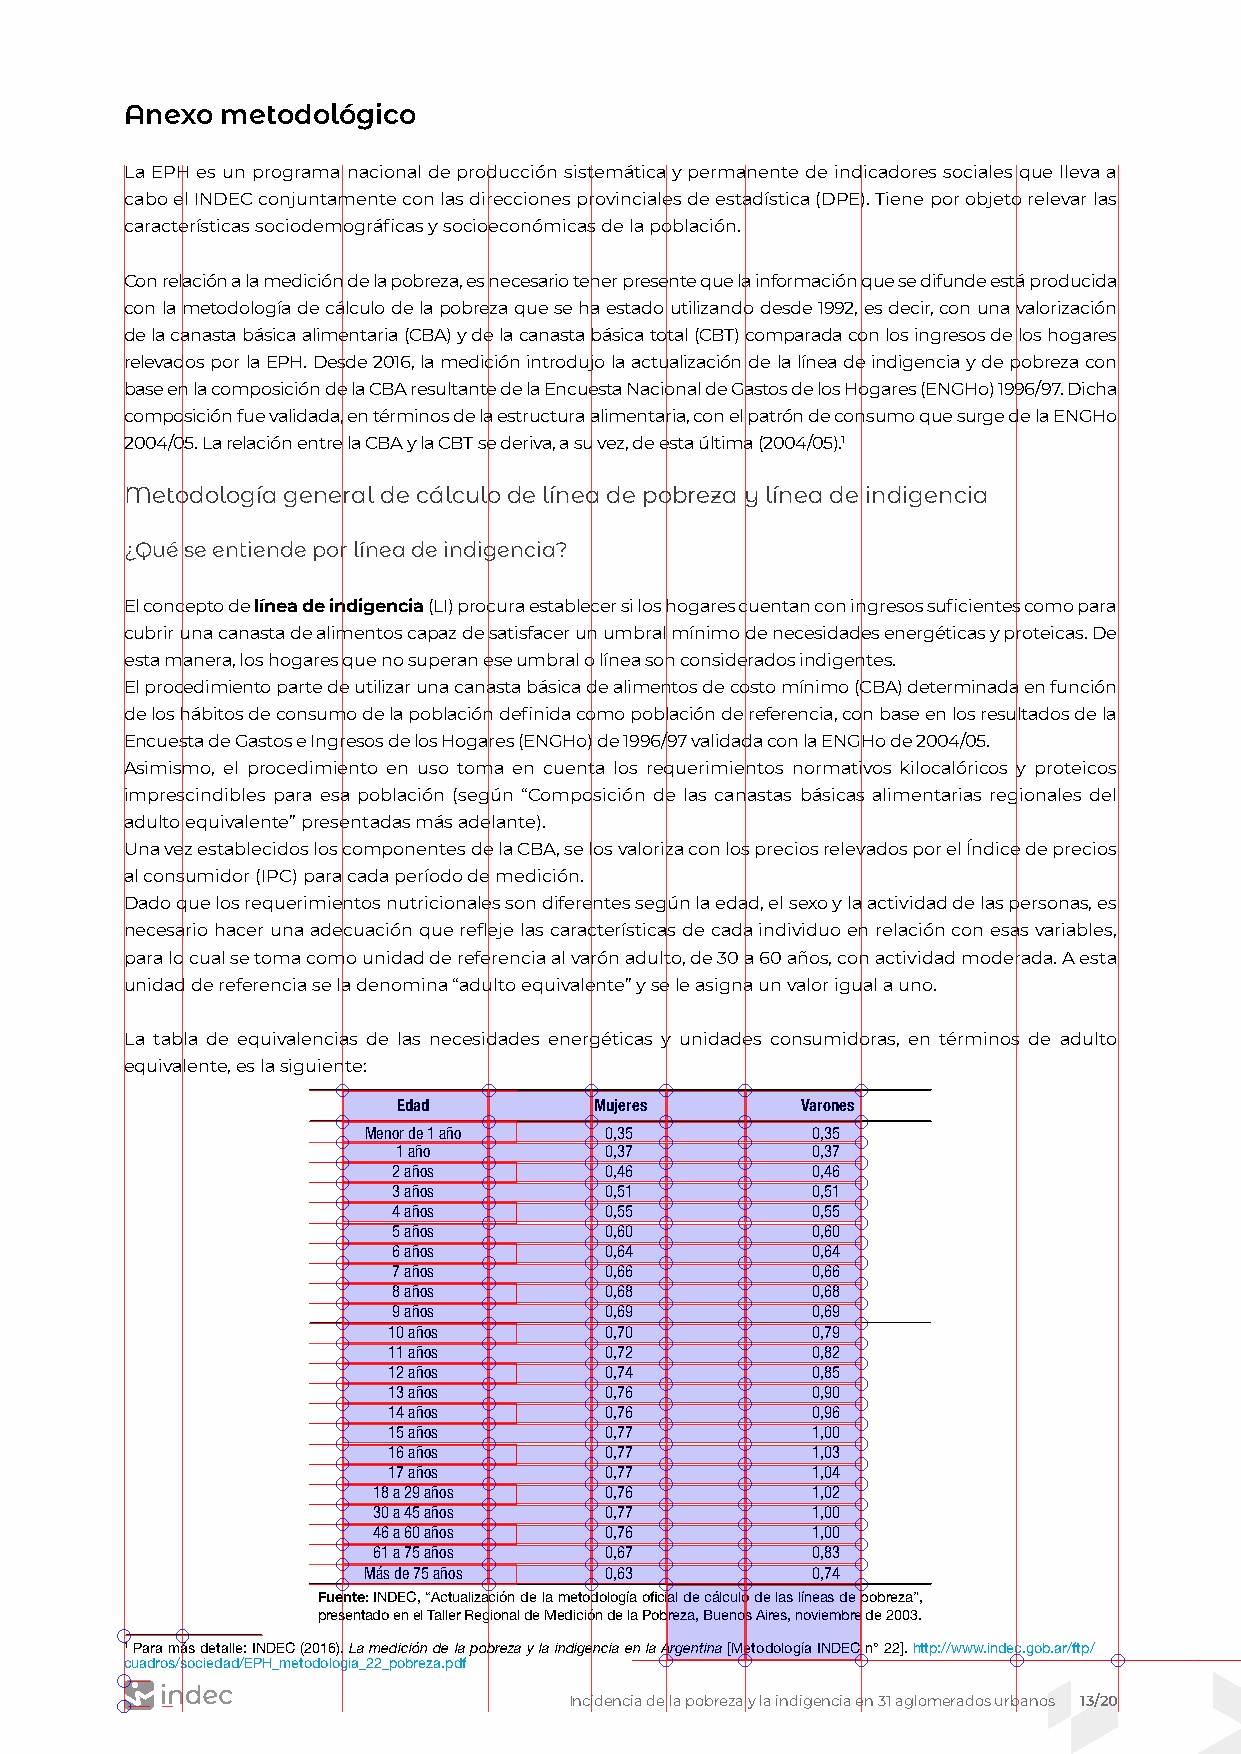

In [23]:
imagen = pagina_plumber_tabla.to_image(resolution=150)

configuracion = dict(
    vertical_strategy = "text",
    horizontal_strategy = "lines",
)

imagen.debug_tablefinder(
    table_settings=configuracion
)

display(imagen)

Y ahora si puedo extraer la tabla

In [11]:
tablas = pagina_plumber_tabla.extract_tables(
    table_settings=configuracion
)

df = pd.DataFrame(tablas[0]).reset_index(drop=True)
display(df)

,0,1,2,3,4
0,Edad,,Mujeres,,Varones
1,Menor de 1 año,,"0,35",,"0,35"
2,1 año,,"0,37",,"0,37"
3,2 años,,"0,46",,"0,46"
4,3 años,,"0,51",,"0,51"
5,4 años,,"0,55",,"0,55"
6,5 años,,"0,60",,"0,60"
7,6 años,,"0,64",,"0,64"
8,7 años,,"0,66",,"0,66"
9,8 años,,"0,68",,"0,68"


La tabla no se arma correctamente. Asique elimino la ultima fila, uso la primera fila como el nombre de las columnas, borro las columnas con indice 1 y 3 y convierto las columnas "Mujeres y "Varones" a float

In [13]:
df = df.iloc[:-1]
df = df.drop(columns=df.columns[[1, 3]])
df.columns = df.iloc[0]
df = df.iloc[1:].reset_index(drop=True)
df[["Mujeres", "Varones"]] = df[["Mujeres", "Varones"]].apply(lambda columna: pd.to_numeric(columna.str.replace(",", ".", regex=False)))

In [14]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 23 entries, 0 to 22
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Edad     23 non-null     str    
 1   Mujeres  23 non-null     float64
 2   Varones  23 non-null     float64
dtypes: float64(2), str(1)
memory usage: 684.0 bytes


In [15]:
df

,Edad,Mujeres,Varones
0,Menor de 1 año,0.35,0.35
1,1 año,0.37,0.37
2,2 años,0.46,0.46
3,3 años,0.51,0.51
4,4 años,0.55,0.55
5,5 años,0.60,0.60
6,6 años,0.64,0.64
7,7 años,0.66,0.66
8,8 años,0.68,0.68
9,9 años,0.69,0.69


## 4. Análisis de frecuencias (NLP básico)

Primero buscamos la pagina deseada.

In [16]:
numero_pagina = 13

pagina_plumber = pdf_plumber.pages[numero_pagina]

In [17]:
texto_pagina = pagina_plumber.extract_text()

In [18]:
texto_pagina

'Se presentan a continuación dos ejemplos de cómo se determina la cantidad de unidades de referencia (adultos\nequivalentes) para cada caso.\nEjemplos\n– Un hogar de tres miembros, compuesto por una mujer de 35 años, su hijo de 18 y su madre de 61:\nLa mujer equivale a 0,77 de adulto equivalente.\nEl hijo equivale a 1,02 de adulto equivalente.\nLa madre equivale a 0,67 de adulto equivalente.\nEn total, el hogar suma 2,46 unidades de referencia o adultos equivalentes.\n– Otro hogar de cinco miembros, constituido por una pareja (ambos de cuarenta años) y tres hijos de cinco, tres\ny un año cumplidos:\nEl varón equivale a 1,00 adulto equivalente.\nLa mujer equivale a 0,77 de adulto equivalente.\nEl hijo de 5 años equivale a 0,60 de adulto equivalente.\nEl hijo de 3 años equivale a 0,51 de adulto equivalente.\nEl hijo de 1 año equivale a 0,37 de adulto equivalente.\nEn total, el hogar suma 3,25 unidades de referencia o adultos equivalentes.\nLa composición de cada hogar en adultos equivale

Traemos las stopwords en español previamente importadas de nltk y le damos un update con la lista proporcionada por la profesora.

In [19]:
stopwords_es = set(stopwords.words('spanish'))
stopwords_es.update(["con", "que", "los", "para", "un", "una", "el", "la", "en", "y", "o", "de", "a", "se", "es", "al", "como", "por", "no", "su", "más", "pero", "si", "este", "esta", "eso", "esa", "todo", "todos", "todas", "cada", "cual", "cualquier", "algo", "alguna", "algún", "ningún", "ninguna", "ninguno", "otro", "otros", "otras", "sobre", "entre", "durante", "desde", "hasta", "también", "así", "mismo", "misma", "mismo", "misma", "tan", "tanto", "tanta", "muy", "poco", "poca", "poco", "nada", "solo", "sola", "solo", "sola", "siempre", "nunca", "jamás", "casi", "aproximadamente", "cerca", "lejos", "antes", "después", "ahora", "hoy", "ayer", "mañana", "luego", "mientras", "mientras tanto", "después de", "antes de", "durante", "sin", "aunque", "a pesar de", "debido a", "gracias a", "por qué", "cómo", "dónde", "cuándo", "quién", "qué", "cuál"])

texto_pagina = texto_pagina.lower() # Pasamos todo el texto a minisculas

Eliminamos stop-words y caracteres extraños del texto, tokenizamos y guardamos en la serie "texto_pagina_sin_stopwords"

In [20]:
texto_pagina = re.sub(r'[^\w\s]', ' ', texto_pagina)
tokens = word_tokenize(texto_pagina, language='spanish')

texto_pagina_sin_stopwords = [palabra for palabra in tokens if palabra not in stopwords_es]

texto_pagina_sin_stopwords = pd.Series(texto_pagina_sin_stopwords)
print(texto_pagina_sin_stopwords.to_string())

0         presentan
1      continuación
2               dos
3          ejemplos
4         determina
5          cantidad
6          unidades
7        referencia
8           adultos
9      equivalentes
10             caso
11         ejemplos
12            hogar
13             tres
14         miembros
15        compuesto
16            mujer
17               35
18             años
19             hijo
20               18
21            madre
22               61
23            mujer
24         equivale
25                0
26               77
27           adulto
28      equivalente
29             hijo
30         equivale
31                1
32               02
33           adulto
34      equivalente
35            madre
36         equivale
37                0
38               67
39           adulto
40      equivalente
41            total
42            hogar
43             suma
44                2
45               46
46         unidades
47       referencia
48          adultos
49     equivalentes


Contamos los valores mas repetidos y guardamos los primeros 15 en una variable y luego la graficamos

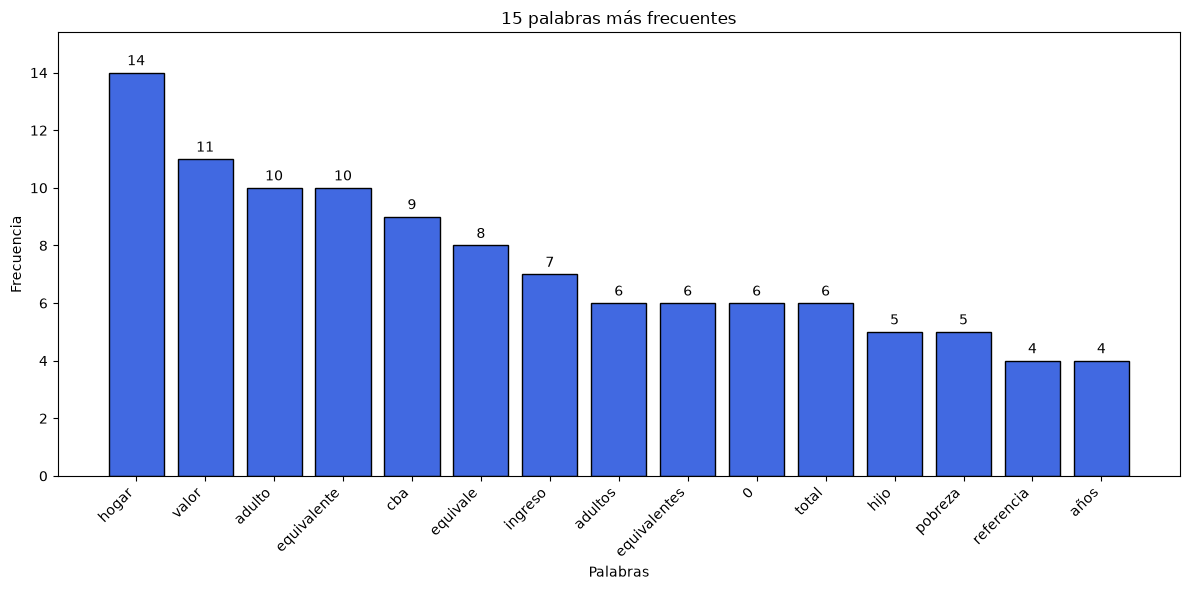

In [21]:
top_15 = texto_pagina_sin_stopwords.value_counts().head(15)

fig, ax = plt.subplots(figsize=(12, 6))

barras = ax.bar(
    top_15.index,
    top_15.values,
    color="royalblue",
    edgecolor="black"
)

ax.bar_label(barras, padding=3)

ax.set_title("15 palabras más frecuentes")
ax.set_xlabel("Palabras")
ax.set_ylabel("Frecuencia")
ax.set_ylim(0, top_15.max() * 1.1)

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Al generar el gráfico de las 15 palabras más frecuentes, se observa que predominan términos relacionados con el cálculo de la pobreza y la indigencia, como "hogar", "valor", "adulto", "equivalente" e "cba"(Canasta Basica Alimenticia).

Si bien no considero que haya palabras que sean stop-words, aparecen variables numéricas que no aportan al análisis de frecuencia de palabras y se ve que términos como "adulto" y "adultos", o "equivalente" y "equivalentes", se contabilizan por separado.

Nose si tomaria alguno de estos valores como stop-words, pero removeria los valores numericos y lematizaria asi los termines como "adulto" y "adultos" que se contabilizan 2 veces cuenten como una sola variable.

Realize este proyecto utilizando el material facilitado por la docente en el aula virtual y
utilize IA para ir refactorizando y corrigiendo el codigo.